In [2]:
! pip install pandas numpy matplotlib seaborn scikit-learn

In [3]:
#Data Loading
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('dataset/WA_Fn-UseC_-Telco-Customer-Churn.csv')

# Show the first 5 rows to prove it worked
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
#  Data Cleaning

# 1. Convert TotalCharges to numeric (it's currently text with some blanks)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# 2. Fill missing TotalCharges with median
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

# 3. Drop customerID (not useful for prediction)
df.drop('customerID', axis=1, inplace=True)

# 4. Convert Churn from Yes/No to 1/0
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# 5. Check for any remaining missing values
print("Missing values after cleaning:", df['TotalCharges'].isnull().sum())

# 6. Show the cleaned data
df.head()

Missing values after cleaning: 0


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


## 3. Exploratory Data Analysis(EDA)

C:\Users\user\AppData\Local\Temp\ipykernel_7684\1499655687.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Churn', data=df, palette='Set2', edgecolor='black')


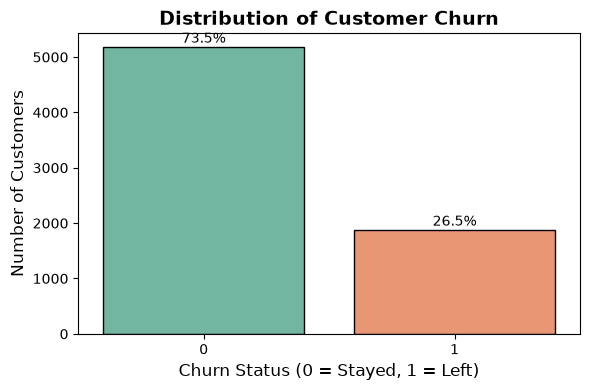

In [5]:
# Visualizing the Target Variable (Class Imbalance)
plt.figure(figsize=(6, 4))
sns.countplot(x='Churn', data=df, palette='Set2', edgecolor='black')
plt.title('Distribution of Customer Churn', fontsize=14, fontweight='bold')
plt.xlabel('Churn Status (0 = Stayed, 1 = Left)', fontsize=12)
plt.ylabel('Number of Customers', fontsize=12)

# Add percentage labels on top of the bars
total = len(df)
for p in plt.gca().patches:
    percentage = f'{100 * p.get_height() / total:.1f}%\n'
    x = p.get_x() + p.get_width() / 2
    y = p.get_height()
    plt.annotate(percentage, (x, y), ha='center', va='center', fontsize=10)

plt.tight_layout()
plt.show()

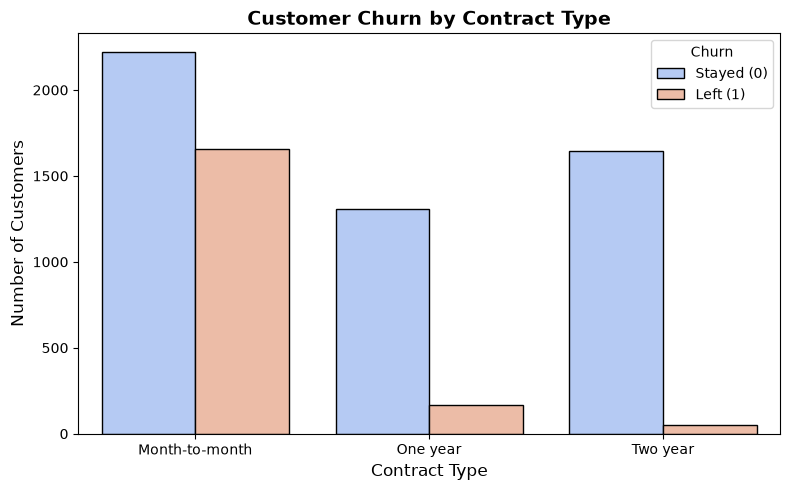

In [6]:
# Churn Rate by Contract Type (The most actionable insight)
plt.figure(figsize=(8, 5))
sns.countplot(x='Contract', hue='Churn', data=df, palette='coolwarm', edgecolor='black')
plt.title('Customer Churn by Contract Type', fontsize=14, fontweight='bold')
plt.xlabel('Contract Type', fontsize=12)
plt.ylabel('Number of Customers', fontsize=12)
plt.legend(title='Churn', labels=['Stayed (0)', 'Left (1)'])
plt.tight_layout()
plt.show()

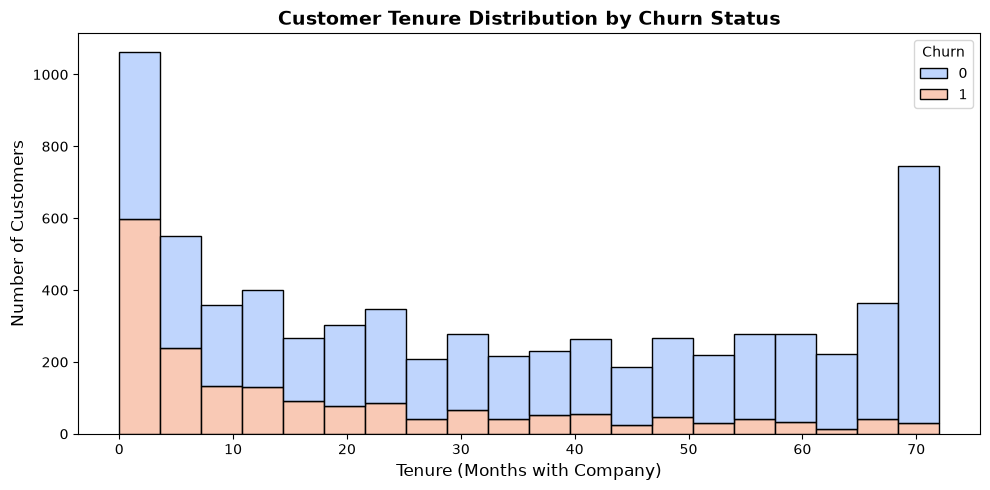

In [7]:
# Tenure Distribution (How long customers stay)
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='tenure', hue='Churn', multiple='stack', bins=20, palette='coolwarm', edgecolor='black')
plt.title('Customer Tenure Distribution by Churn Status', fontsize=14, fontweight='bold')
plt.xlabel('Tenure (Months with Company)', fontsize=12)
plt.ylabel('Number of Customers', fontsize=12)
plt.tight_layout()
plt.show()

## 5. Data Preprocessing & Train/Test Split

In [8]:
# Cell 7: Preparing Data for Machine Learning

df_model = df.drop('tenure', axis=1)

df_encoded = pd.get_dummies(df_model, drop_first=True, dtype=int)

X = df_encoded.drop('Churn', axis=1)
y = df_encoded['Churn']

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data Preparation Complete!")
print(f"Training set size: {X_train_scaled.shape[0]} rows")
print(f"Testing set size: {X_test_scaled.shape[0]} rows")
print(f"Total features created: {X_train_scaled.shape[1]}")

Data Preparation Complete!
Training set size: 5634 rows
Testing set size: 1409 rows
Total features created: 29


## 6. Machine Learning Model Training & Evaluation

In [9]:
# Cell 8: Training the Models

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# --- MODEL 1: Logistic Regression (The Baseline) ---
# We use class_weight='balanced' because fewer people churn than stay.
lr_model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
lr_model.fit(X_train_scaled, y_train)
lr_preds = lr_model.predict(X_test_scaled)

# --- MODEL 2: Random Forest (The Advanced Model) ---
rf_model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
rf_model.fit(X_train_scaled, y_train)
rf_preds = rf_model.predict(X_test_scaled)

# --- EVALUATION ---
print("=== 1. LOGISTIC REGRESSION (Baseline) ===")
print(f"Accuracy: {accuracy_score(y_test, lr_preds):.4f}\n")
print(classification_report(y_test, lr_preds, target_names=['Stayed (0)', 'Churned (1)']))

print("=== 2. RANDOM FOREST (Advanced) ===")
print(f"Accuracy: {accuracy_score(y_test, rf_preds):.4f}\n")
print(classification_report(y_test, rf_preds, target_names=['Stayed (0)', 'Churned (1)']))

=== 1. LOGISTIC REGRESSION (Baseline) ===
Accuracy: 0.7331

              precision    recall  f1-score   support

  Stayed (0)       0.90      0.72      0.80      1035
 Churned (1)       0.50      0.77      0.61       374

    accuracy                           0.73      1409
   macro avg       0.70      0.75      0.70      1409
weighted avg       0.79      0.73      0.75      1409

=== 2. RANDOM FOREST (Advanced) ===
Accuracy: 0.7630

              precision    recall  f1-score   support

  Stayed (0)       0.86      0.81      0.83      1035
 Churned (1)       0.55      0.63      0.59       374

    accuracy                           0.76      1409
   macro avg       0.70      0.72      0.71      1409
weighted avg       0.78      0.76      0.77      1409



## 7. Model Performance Visualization

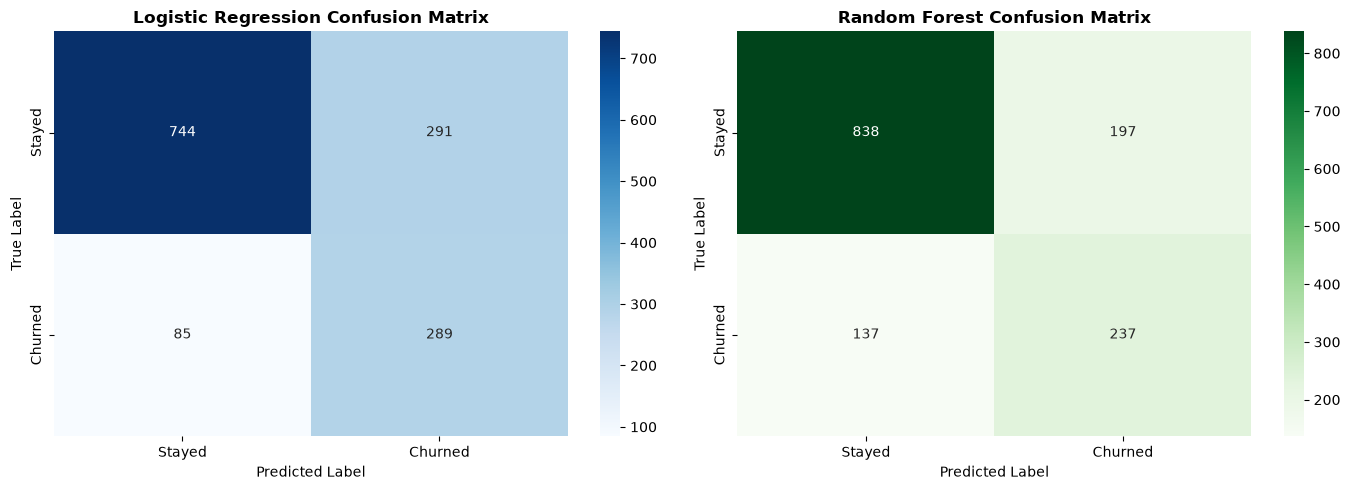

In [10]:
# Cell 9: Confusion Matrix Visualization

from sklearn.metrics import confusion_matrix

# Create a side-by-side plot for both models
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Plot 1: Logistic Regression ---
cm_lr = confusion_matrix(y_test, lr_preds)
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Stayed', 'Churned'], yticklabels=['Stayed', 'Churned'])
axes[0].set_title('Logistic Regression Confusion Matrix', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# --- Plot 2: Random Forest ---
cm_rf = confusion_matrix(y_test, rf_preds)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['Stayed', 'Churned'], yticklabels=['Stayed', 'Churned'])
axes[1].set_title('Random Forest Confusion Matrix', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.tight_layout()
plt.show()

## 8. Feature Importance: What Drives Churn?

C:\Users\user\AppData\Local\Temp\ipykernel_7684\3929640510.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importance_df.head(10), palette='viridis')


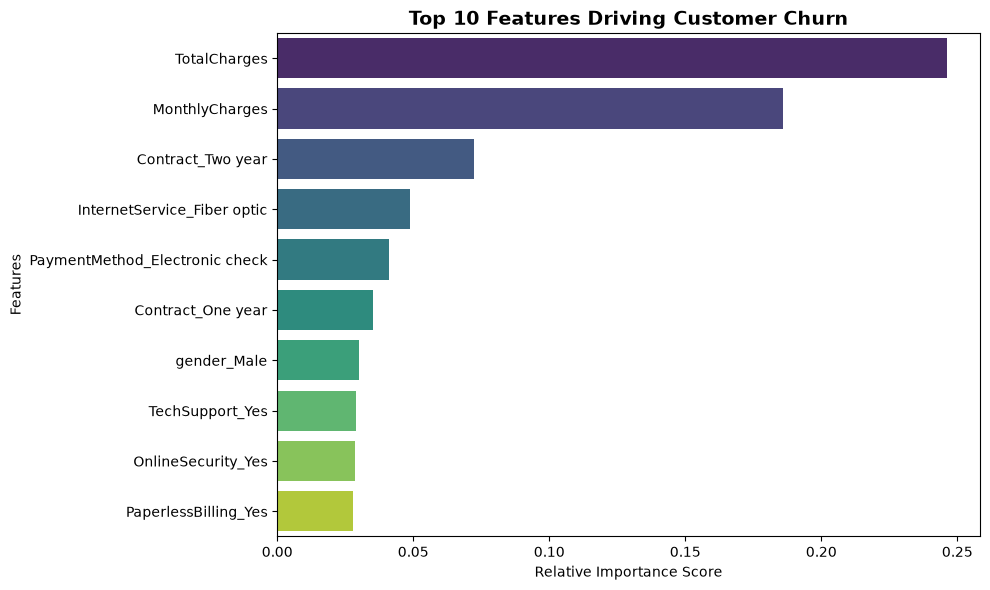

--- Top 5 Churn Drivers ---


,Feature,Importance
2,TotalCharges,0.246024
1,MonthlyCharges,0.185923
24,Contract_Two year,0.072288
9,InternetService_Fiber optic,0.048838
27,PaymentMethod_Electronic check,0.040985


In [11]:
# Cell 10: Feature Importance from Random Forest

# 1. Extract the importance scores from the trained Random Forest model
importances = rf_model.feature_importances_

# 2. Create a DataFrame to match the importance scores with the actual column names
feature_names = X.columns
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

# 3. Sort the features from most important to least important
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df.head(10), palette='viridis')
plt.title('Top 10 Features Driving Customer Churn', fontsize=14, fontweight='bold')
plt.xlabel('Relative Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

print("--- Top 5 Churn Drivers ---")
display(feature_importance_df.head(5))